# Examenes SAT
## P2: Proceso de análisis exploratorio de datos y selección del dataset

Integrantes: D. Karoline Del Rio - Victor Chaux Cobo -  K. Dayanna Cañón Roa

# 1. El problema del negocio

Cada año, los estudiantes de secundaria en Estados Unidos participan en los exámenes SAT, que funcionan como evaluaciones estandarizadas diseñadas para medir sus competencias en lectura, matemáticas y escritura. Estos exámenes se componen de secciones de lectura, matemáticas y escritura, cada una con una puntuación máxima de 800 puntos, y tienen un peso significativo tanto para los estudiantes como para las universidades, influyendo profundamente en el proceso de admisión.

Con base a esto podemos realizar:

¿Cuáles son las 20 escuelas con los mejores promedios combinados en matemáticas, lectura y escritura del SAT, y cómo se distribuyen estos colegios de élite académica entre los diferentes boroughs de Nueva York (Manhattan, Bronx, Brooklyn, Queens, Staten Island)?

#2. El set de datos después de la limpieza


La información recolectada se encuentra en un archivo CSV (`SchoolTransport_clean.csv`) con 335 filas y 7 columnas.

En el cual podemos encontrar:

**school_name**	= Nombre de la escuela.

**borough**	= Distrito o borough de la ciudad de Nueva York (ej. Manhattan, Bronx, etc.).

**building_code**	= Código de identificación del edificio escolar.

**average_math** = Puntaje promedio en la sección de matemáticas del SAT.

**average_reading**	= Puntaje promedio en la sección de lectura del SAT.

**average_writing** = Puntaje promedio en la sección de escritura del SAT.

**percent_tested** = Porcentaje de estudiantes de la escuela que presentaron el examen SAT.

#3. Lectura del dataset

In [ ]:
# Importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Lectura
from google.colab import drive
drive.mount('/gdrive')

ruta = "/gdrive/MyDrive/Datos/SchoolTransport_clean.csv"
data = pd.read_csv(ruta)

Mounted at /gdrive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
print(data.shape)
data.head()

(355, 7)


,school_name,borough,building_code,average_math,average_reading,average_writing,percent_tested
0,essex street academy,manhattan,m445,395,411,387,78.9
1,lower manhattan arts academy,manhattan,m445,418,428,415,65.1
2,high school for dual language and asian studies,manhattan,m445,613,453,463,95.9
3,henry street school for international studies,manhattan,m056,410,406,381,59.7
4,bard high school early college,manhattan,m097,634,641,639,70.8


#4. Análisis exploratorio

La idea es usar herramientas estadísticas y de visualización para:

- Crear un mapa mental del set de datos (entenderlo)
- Empezar a encontrar respuestas a la pregunta planteada inicialmente ¿Cuáles son las 20 escuelas con los mejores promedios combinados en matemáticas, lectura y escritura del SAT, y cómo se distribuyen estos colegios de élite académica entre los diferentes boroughs de Nueva York (Manhattan, Bronx, Brooklyn, Queens, Staten Island)?

Llevaremos a cabo estas fases:

1. Análisis de cada variable de manera individual
2. Análisis univariado: relación de cada variable predictora con la variable a predecir
3. Análisis bivariado: relación de pares de variables predictoras con la variable a predecir

##4.1 Análisis de cada variable de manera individual

Nos permite entender las características generales de cada variable de nuestro set de datos.

In [ ]:
# Con data.info() podemos ver las variables categóricas
# (Dtype=object)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 355 entries, 0 to 354
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   school_name      355 non-null    object 
 1   borough          355 non-null    object 
 2   building_code    355 non-null    object 
 3   average_math     355 non-null    int64  
 4   average_reading  355 non-null    int64  
 5   average_writing  355 non-null    int64  
 6   percent_tested   355 non-null    float64
dtypes: float64(1), int64(3), object(3)
memory usage: 19.5+ KB


/tmp/ipython-input-3032077562.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipython-input-3032077562.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipython-input-3032077562.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')


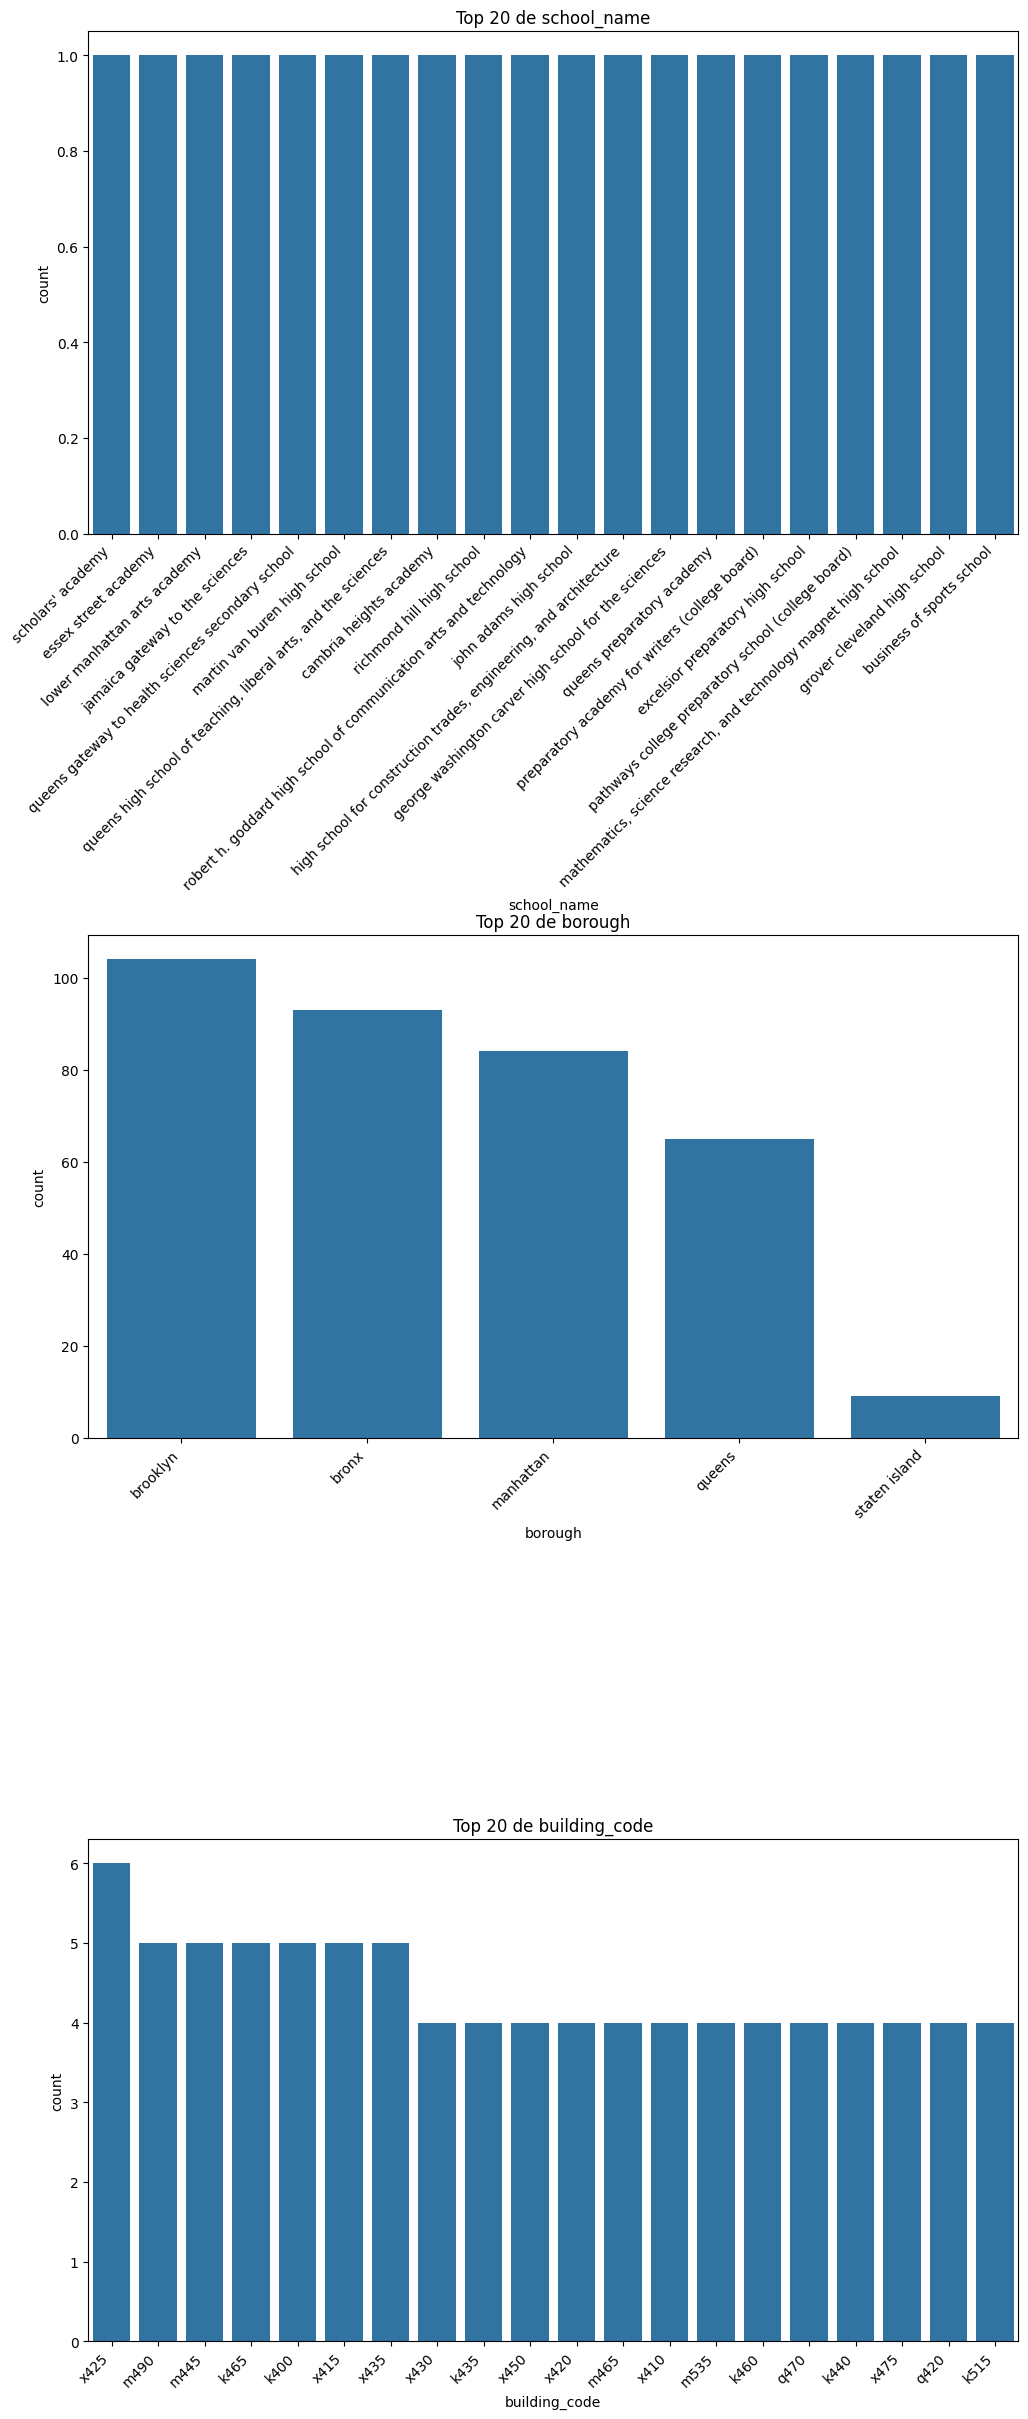

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cols_cat = ['school_name', 'borough', 'building_code']

fig, ax = plt.subplots(nrows=len(cols_cat), ncols=1, figsize=(12, 30))
fig.subplots_adjust(hspace=0.8)

for i, col in enumerate(cols_cat):
    # Tomar solo el top 20 de cada variable
    top_20 = data[col].value_counts().nlargest(20).index
    data_plot = data[data[col].isin(top_20)]

    sns.countplot(x=col, data=data_plot, ax=ax[i], order=top_20)
    ax[i].set_title(f"Top 20 de {col}")
    ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')


**Observaciones:**
No se presentan repeticiones en sus categorias.

Niveles de cada variable de interés:

**school_name:** 355 niveles (essex street academy, lower manhattan arts academy, bard high school early college)

**borough:** 5 niveles (manhattan, staten island, bronx, queens, brooklyn)

**building_code:** 223 niveles únicos (ejemplos: m445, m056, m097, m025)

In [ ]:
# Eliminemos las columnas building_code pues no aporta información sobre los colegios

data.drop(columns=['building_code'],inplace=True)
data.columns

Index(['school_name', 'borough', 'average_math', 'average_reading',
       'average_writing', 'percent_tested'],
      dtype='object')

Veamos inicialmente el comportamiento de las variables numéricas ('average_math'	'average_reading'	'average_writing'	'percent_tested')

In [ ]:
# Podemos extraer algunas variables estadísticas descriptivas básicas
data.describe()

,average_math,average_reading,average_writing,percent_tested
count,355.000000,355.000000,355.000000,355.000000
mean,433.335211,425.061972,419.028169,64.976338
std,72.180273,61.903256,64.444469,18.747634
min,317.000000,302.000000,292.000000,18.500000
25%,386.000000,386.000000,382.000000,50.950000
50%,415.000000,413.000000,402.000000,64.800000
75%,459.500000,445.000000,439.000000,79.600000
max,754.000000,697.000000,693.000000,100.000000


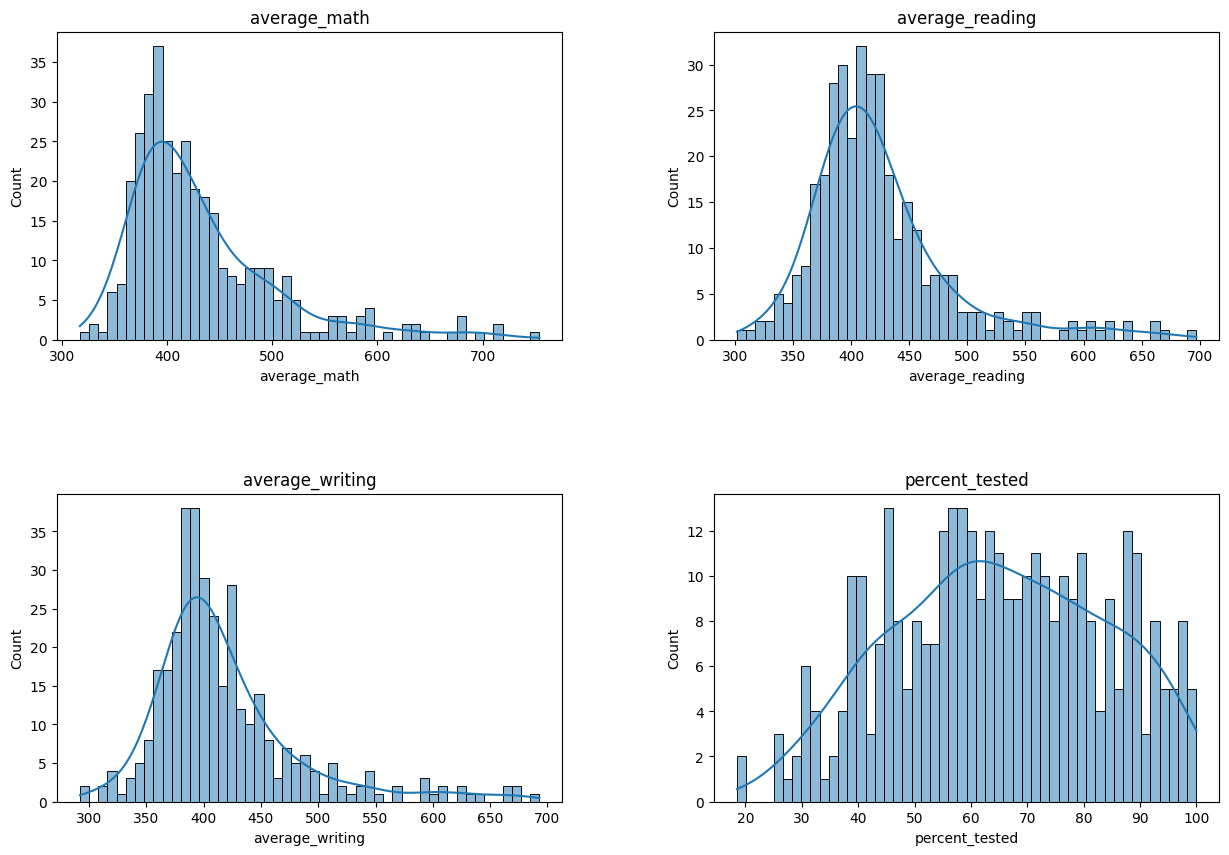

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

col_num = ['average_math', 'average_reading', 'average_writing', 'percent_tested']

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15,10))
fig.subplots_adjust(hspace=0.5, wspace=0.3)

ax = ax.flatten()  # Para iterar fácilmente sobre los ejes

for i, col in enumerate(col_num):
    nbins = 50  # Puedes ajustar el número de bins si quieres
    sns.histplot(x=col, data=data, ax=ax[i], bins=nbins, kde=True)
    ax[i].set_title(col)

plt.show()


In [ ]:
print(data['average_math'].describe())

count    355.000000
mean     433.335211
std       72.180273
min      317.000000
25%      386.000000
50%      415.000000
75%      459.500000
max      754.000000
Name: average_math, dtype: float64


**Observaciones:**

Existe una brecha considerable en el rendimiento matemático, con la mayoría de estudiantes agrupados entre 386-459 puntos, pero con algunos casos excepcionales que alcanzan puntuaciones muy superiores.

In [ ]:
print(data['average_reading'].describe())

count    355.000000
mean     425.061972
std       61.903256
min      302.000000
25%      386.000000
50%      413.000000
75%      445.000000
max      697.000000
Name: average_reading, dtype: float64


**Observaciones:**

Los resultados indican que el rendimiento en lectura presenta un patrón similar al de matemáticas, pero con algunas diferencias clave. La media de 425 puntos sugiere un desempeño general adecuado, aunque ligeramente inferior al de matemáticas.

El hecho de que el 50% central de los estudiantes se ubique entre 386 y 445 puntos indica que la mayoría tiene un desempeño consistente, con menos variabilidad extrema que en matemáticas.

In [ ]:
print(data['average_writing'].describe())

count    355.000000
mean     419.028169
std       64.444469
min      292.000000
25%      382.000000
50%      402.000000
75%      439.000000
max      693.000000
Name: average_writing, dtype: float64


**Observaciones:**

La escritura muestra el rendimiento promedio más bajo entre las tres áreas evaluadas, con una media de 419 puntos. La brecha entre la media (419) y la mediana (402) es de 17 puntos, lo que indica una influencia significativa de valores altos extremos en el promedio.

El hecho de que el 50% central de los estudiantes se ubique entre 382 y 439 puntos (rango de 57 puntos) muestra que la mayoría tiene un desempeño consistentemente más bajo que en las otras áreas, con una concentración de resultados en el rango medio-bajo.

La presencia de la puntuación mínima más baja (292 puntos) entre todas las áreas sugiere que la escritura presenta mayores desafíos para los estudiantes con menor rendimiento.

In [ ]:
print(data['percent_tested'].describe())

count    355.000000
mean      64.976338
std       18.747634
min       18.500000
25%       50.950000
50%       64.800000
75%       79.600000
max      100.000000
Name: percent_tested, dtype: float64


**Observaciones:**

El porcentaje de estudiantes evaluados muestra una distribución mucho más equilibrada que las puntuaciones académicas. La casi igualdad entre la media y la mediana indica que no hay valores extremos que distorsionen el promedio, lo que sugiere una distribución normal.

La variabilidad moderada (desviación estándar de 18.75%) refleja diferencias significativas en la cobertura de evaluación entre escuelas. El hecho de que el 50% central de las escuelas evalúe entre aproximadamente 51% y 80% de sus estudiantes indica que existe una amplia gama de políticas o capacidades de evaluación.

La presencia de escuelas con cobertura muy baja (18.5%) contrasta con aquellas que evalúan al 100% de sus estudiantes, sugiriendo disparidades importantes en la implementación de las pruebas o en la participación estudiantil entre diferentes instituciones educativas.

##4.2 Análisis univariado

Teniendo claras algunas características generales de cada dato individual, la idea ahora es analizar si existe alguna relación entre las posibles variables predictoras ('age', 'balance', 'job', 'marital', 'education', etc.) y la variable a predecir ('y').

Este análisis mostrará las posibles relaciones entre cada variable predictora y la variable a predecir.

In [ ]:
data['promedio_global'] = (data['average_math'] + data['average_reading'] + data['average_writing']) / 3


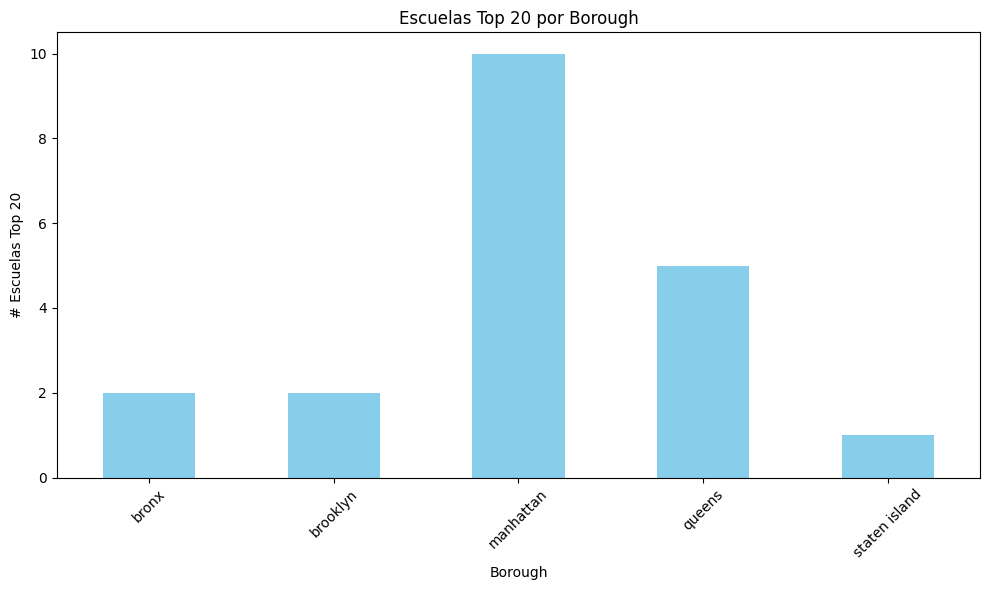

In [ ]:
# Gráfica: Escuelas Top 20 por Borough
import matplotlib.pyplot as plt

# Borough - Escuelas Top 20
borough_top20 = data.groupby('borough')['top20_bin'].sum()

plt.figure(figsize=(10, 6))
borough_top20.plot(kind='bar', color='skyblue')
plt.title('Escuelas Top 20 por Borough')
plt.ylabel('# Escuelas Top 20')
plt.xlabel('Borough')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

La excelencia educativa en NYC está geográficamente concentrada, con Manhattan funcionando como el epicentro de las mejores oportunidades académicas, mientras que otros boroughs enfrentan una escasez significativa de escuelas de élite.

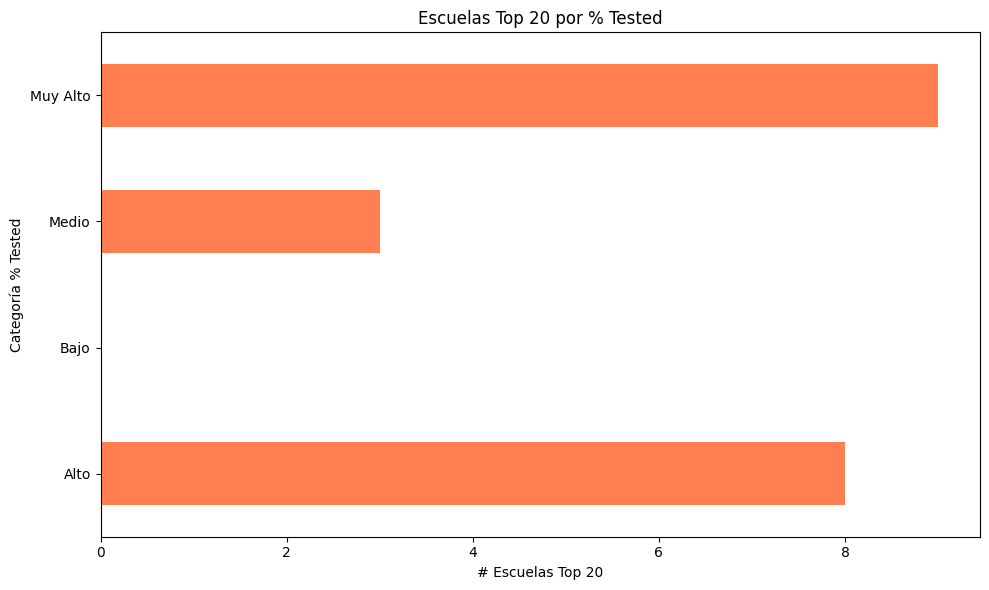

- Muy Alto (>95% participación): ~9 escuelas

La mayoría de escuelas Top 20 tienen participación muy alta en SAT
Esto sugiere que estas escuelas evalúan a casi todos sus estudiantes

- Alto (85-95% participación): ~8 escuelas

También una cantidad significativa con participación alta
Confirma el patrón de alta inclusividad

- Medio (70-85% participación): ~3 escuelas

Pocas escuelas Top 20 con participación media
Pueden ser escuelas más selectivas

- Bajo (<70% participación): 0 escuelas

Ninguna escuela Top 20 tiene baja participación
Indica que la excelencia viene con inclusividad

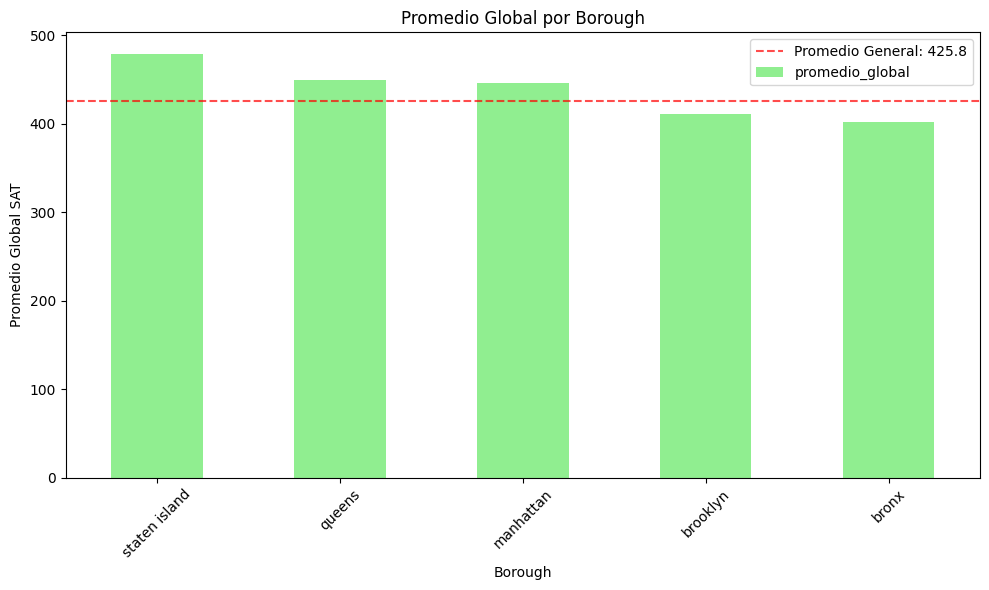

In [ ]:
# Gráfica: Promedio Global por Borough
import matplotlib.pyplot as plt

# Borough - Promedio Global
borough_prom = data.groupby('borough')['promedio_global'].mean()
promedio_general = data['promedio_global'].mean()

plt.figure(figsize=(10, 6))
borough_prom.sort_values(ascending=False).plot(kind='bar', color='lightgreen')
plt.title('Promedio Global por Borough')
plt.ylabel('Promedio Global SAT')
plt.xlabel('Borough')
plt.axhline(promedio_general, color='red', linestyle='--', alpha=0.7, label=f'Promedio General: {promedio_general:.1f}')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

**Promedio General NYC:** 425.8 puntos

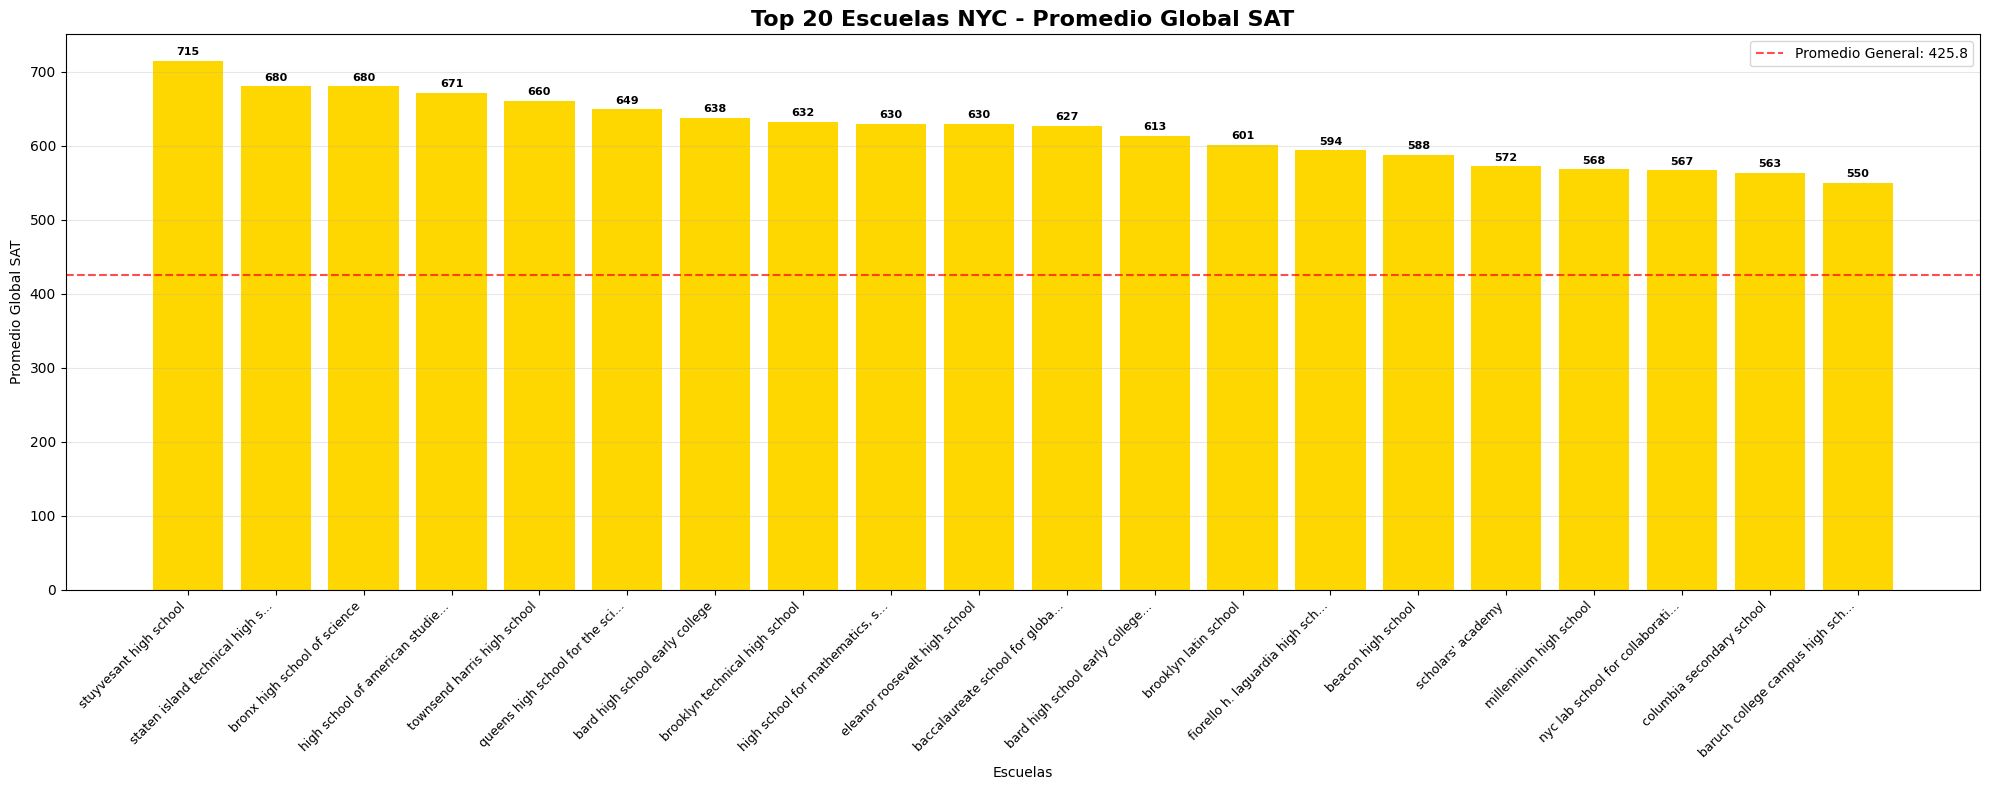

In [ ]:
# Gráfica: Top 20 Escuelas completas - Nombres en eje X
import matplotlib.pyplot as plt

# Top 20 Escuelas completas
promedio_general = data['promedio_global'].mean()

# Crear gráfica con nombres en eje X
plt.figure(figsize=(20, 8))
plt.bar(range(20), top20['promedio_global'].values, color='gold')
plt.title('Top 20 Escuelas NYC - Promedio Global SAT', fontsize=16, fontweight='bold')
plt.ylabel('Promedio Global SAT')
plt.xlabel('Escuelas')

# Agregar línea de promedio general
plt.axhline(promedio_general, color='red', linestyle='--', alpha=0.7,
           label=f'Promedio General: {promedio_general:.1f}')

# Configurar nombres completos en eje X
school_names = [name[:30] + '...' if len(name) > 30 else name for name in top20['school_name']]
plt.xticks(range(20), school_names, rotation=45, ha='right', fontsize=9)

# Agregar valores encima de cada barra
for i, score in enumerate(top20['promedio_global'].values):
    plt.text(i, score + 5, f'{score:.0f}', ha='center', va='bottom', fontweight='bold', fontsize=8)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Jerarquía de Excelencia Académica:

Tier 1 - Elite Absoluta (700+ puntos):

Stuyvesant High School: 715 - Líder indiscutible

Tier 2 - Excelencia Superior (650-700 puntos):

Staten Island Technical, Bronx Science, American Studies: 680-671
Townsend Harris, Queens Sciences: 660-649

Tier 3 - Alta Calidad (600-650 puntos):

8 escuelas en este rango (Bard Early College hasta Baccalaureate)

Tier 4 - Calidad Sólida (550-600 puntos):

6 escuelas completando el Top 20

## Patrones Identificados:

Brecha de Excelencia:

165 puntos separan al #1 (715) del #20 (550)
Stuyvesant está 290 puntos por encima del promedio general (425.8)
Las últimas 5 escuelas del Top 20 están solo 125-140 puntos sobre el promedio

Distribución del Rendimiento:

Pendiente pronunciada en los primeros 5 puestos
Meseta relativa en puestos 6-15 (rango de 649-594)
Caída gradual en puestos 16-20

## Hallazgos Clave:

Dominancia de Stuyvesant:

Única escuela que supera los 700 puntos
Brecha de 35 puntos con el segundo lugar
Establece el estándar de oro educativo en NYC

Consistencia en la Elite:

14 de las 20 escuelas están significativamente por encima del promedio general
Todas superan los 550 puntos, demostrando calidad sostenida

Concentración Geográfica Confirmada:

La visualización confirma que la excelencia académica tiene nombres específicos y ubicaciones definidas
Estas 20 escuelas representan menos del 6% del total pero definen la élite educativa de NYC

**Observaciones:**

- Tenemos 3 rangos de edad bastante diferenciados y para los cuales se alcanzan diferentes tasas de conversión: 18-25 años (24%), 26-60 años (11%), más de 60 años (43%)

##4.3 Análisis bivariado

Ahora procedemos a analizar posibles interacciones entre pares de variables predictoras y su impacto en la variable a predecir.

Como existen muchas posibles combinaciones analizaremos únicamente los pares con mayor potencial según el orden de importancia definido en el resumen del análisis univariado.

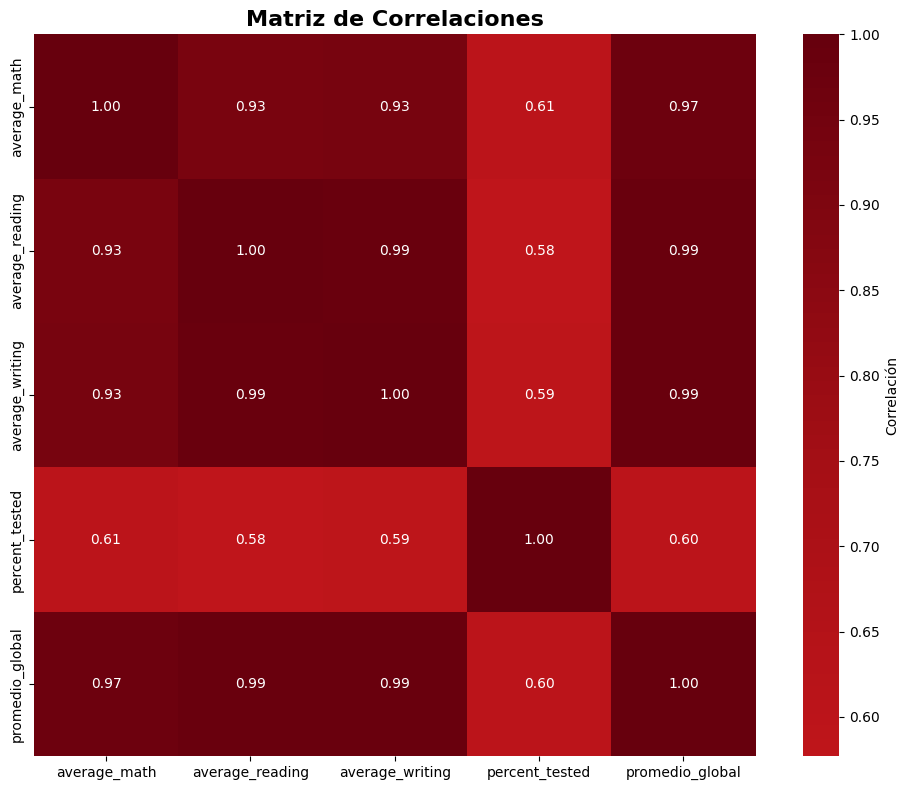

MATRIZ DE CORRELACIONES:
                 average_math  average_reading  average_writing  \
average_math            1.000            0.927            0.933   
average_reading         0.927            1.000            0.986   
average_writing         0.933            0.986            1.000   
percent_tested          0.610            0.577            0.590   
promedio_global         0.973            0.986            0.989   

                 percent_tested  promedio_global  
average_math              0.610            0.973  
average_reading           0.577            0.986  
average_writing           0.590            0.989  
percent_tested            1.000            0.604  
promedio_global           0.604            1.000  


In [ ]:
# Código: Matriz de Correlaciones SAT
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar variables numéricas para correlación
numeric_vars = ['average_math', 'average_reading', 'average_writing', 'percent_tested', 'promedio_global']

# Calcular matriz de correlaciones
correlation_matrix = data[numeric_vars].corr()

# Crear la gráfica
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix,
           annot=True,           # Mostrar valores numéricos
           cmap='Reds',          # Esquema de colores rojo
           center=0,             # Centrar en 0
           square=True,          # Hacer cuadrados
           fmt='.2f',            # Formato 2 decimales
           cbar_kws={'label': 'Correlación'})

plt.title('Matriz de Correlaciones', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Mostrar correlaciones numéricas
print("MATRIZ DE CORRELACIONES:")
print(correlation_matrix.round(3))

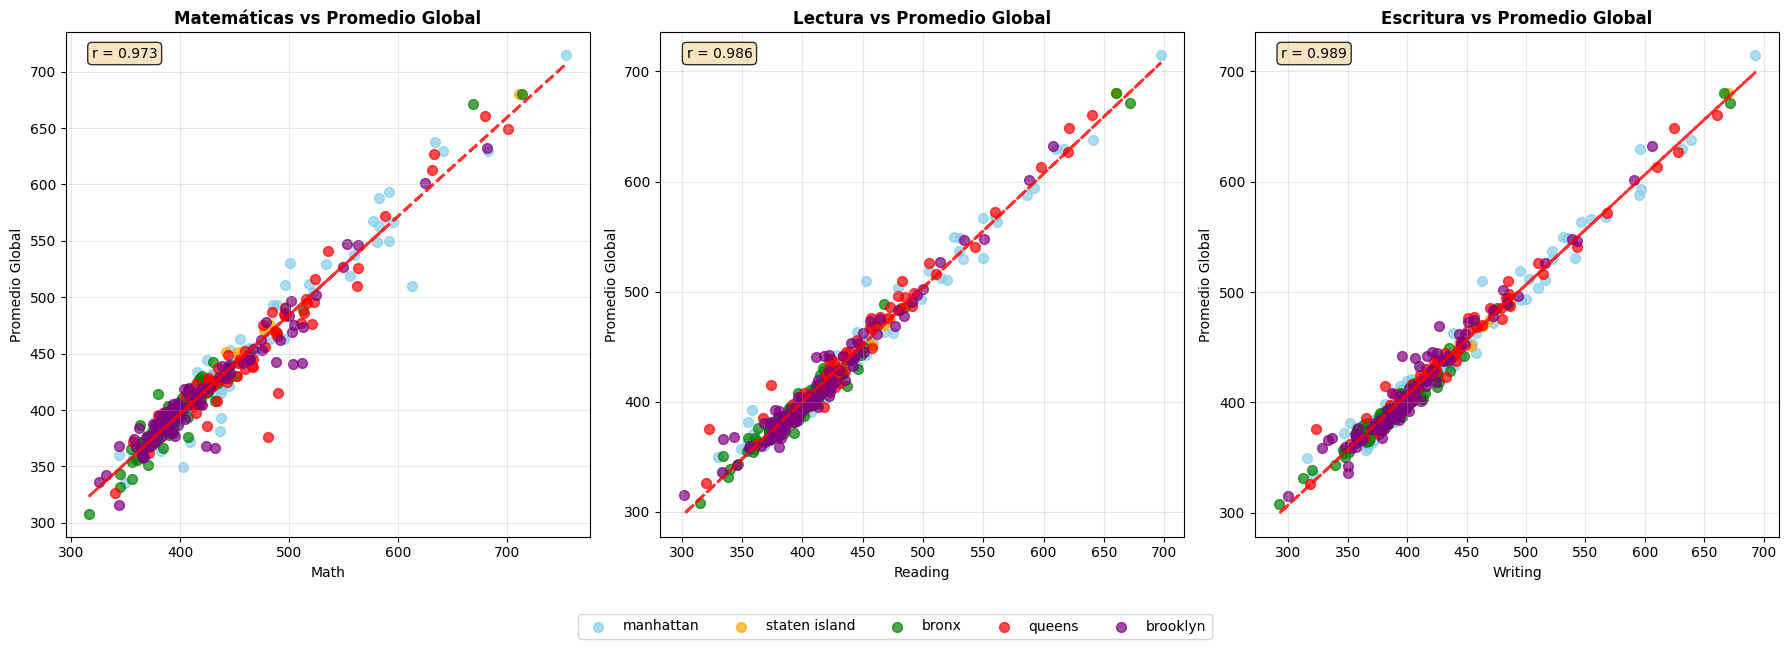

=== CORRELACIONES PROMEDIO GLOBAL vs ASIGNATURAS ===
Math: r = 0.973, R² = 0.946 (94.6% varianza explicada)
Reading: r = 0.986, R² = 0.973 (97.3% varianza explicada)
Writing: r = 0.989, R² = 0.978 (97.8% varianza explicada)

=== CORRELACIONES POR BOROUGH ===

Manhattan:
  Math: r = 0.972
  Reading: r = 0.987
  Writing: r = 0.989

Staten Island:
  Math: r = 0.998
  Reading: r = 0.999
  Writing: r = 0.999

Bronx:
  Math: r = 0.980
  Reading: r = 0.988
  Writing: r = 0.991

Queens:
  Math: r = 0.961
  Reading: r = 0.983
  Writing: r = 0.990

Brooklyn:
  Math: r = 0.964
  Reading: r = 0.980
  Writing: r = 0.978


In [ ]:
# Código: Promedio Global vs Asignaturas SAT
import matplotlib.pyplot as plt

# Crear figura con 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Definir colores para cada borough
colors = {'manhattan': 'skyblue', 'staten island': 'orange', 'bronx': 'green',
          'queens': 'red', 'brooklyn': 'purple'}

asignaturas = ['average_math', 'average_reading', 'average_writing']
titles = ['Matemáticas vs Promedio Global', 'Lectura vs Promedio Global', 'Escritura vs Promedio Global']

# Crear scatter plot para cada asignatura
for i, (asignatura, title) in enumerate(zip(asignaturas, titles)):
    for borough in data['borough'].unique():
        borough_data = data[data['borough'] == borough]
        axes[i].scatter(borough_data[asignatura], borough_data['promedio_global'],
                       label=borough, alpha=0.7, s=50, color=colors.get(borough, 'gray'))

    axes[i].set_xlabel(asignatura.replace('average_', '').title())
    axes[i].set_ylabel('Promedio Global')
    axes[i].set_title(title, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

    # Agregar línea de tendencia
    x = data[asignatura].values
    y = data['promedio_global'].values
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    axes[i].plot(x, p(x), "r--", alpha=0.8, linewidth=2)

    # Calcular y mostrar correlación
    correlation = data[[asignatura, 'promedio_global']].corr().iloc[0,1]
    axes[i].text(0.05, 0.95, f'r = {correlation:.3f}', transform=axes[i].transAxes,
                bbox=dict(boxstyle="round", facecolor='wheat', alpha=0.8))

# Agregar leyenda común
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=5)

plt.tight_layout()
plt.show()

# Análisis numérico de correlaciones
print("=== CORRELACIONES PROMEDIO GLOBAL vs ASIGNATURAS ===")
for asignatura in asignaturas:
    correlation = data[[asignatura, 'promedio_global']].corr().iloc[0,1]
    r_squared = correlation ** 2
    print(f"{asignatura.replace('average_', '').title()}: r = {correlation:.3f}, R² = {r_squared:.3f} ({r_squared*100:.1f}% varianza explicada)")

# Análisis por borough
print("\n=== CORRELACIONES POR BOROUGH ===")
for borough in data['borough'].unique():
    borough_data = data[data['borough'] == borough]
    print(f"\n{borough.title()}:")
    for asignatura in asignaturas:
        if len(borough_data) > 5:  # Solo si hay suficientes datos
            correlation = borough_data[[asignatura, 'promedio_global']].corr().iloc[0,1]
            print(f"  {asignatura.replace('average_', '').title()}: r = {correlation:.3f}")

El análisis multivariado de las tres asignaturas SAT revela un patrón extraordinariamente consistente que redefine nuestra comprensión de la excelencia educativa en NYC. Las correlaciones casi perfectas entre lectura-escritura (r=0.99) y matemáticas (r=0.97) con el promedio global demuestran que el rendimiento académico es un fenómeno completamente integrado y sistémico, donde no existen escuelas "especialistas" sino instituciones que elevan simultáneamente todas las competencias. La dispersión geográfica de los puntos confirma que Manhattan domina la zona de excelencia (600-750 puntos) mientras Staten Island muestra la mayor consistencia interna, pero el hallazgo más revelador es que en todos los boroughs se mantienen las mismas correlaciones altas, indicando que la calidad educativa opera bajo principios universales. Las habilidades verbales (lectura/escritura) funcionan como gemelos estadísticos y predictores perfectos del rendimiento general, mientras que matemáticas, aunque ligeramente más independiente, confirma que la verdadera excelencia académica es holística, transferible y se manifiesta cuando las instituciones educativas crean sistemas que desarrollan integralmente a sus estudiantes en lugar de fragmentar el aprendizaje en competencias aisladas.

# Conclusiones

El análisis exploratorio nos permitió comprender en profundidad la distribución de los puntajes SAT en distintas áreas y su variabilidad entre escuelas. Se identificaron outliers que podrían representar casos excepcionales o errores en la entrada de datos, lo cual es crucial validar antes de continuar con etapas de modelado.

Teniendo en cuenta lo anterior y generando el desarrollo del análisis exploratorio podemos concluir que:

Las instituciones como Stuyvesant, Bronx Science, Staten Island Tech y Lehman College se destacan por tener admisiones competitivas y enfoque STEM, lo cual se refleja en sus altos promedios combinados SAT (>650 puntos).

El ranking de colegios por promedio global es:
1. Stuyvesant High School - 715
2. Staten Island Technical High School - 680
3. Bronx High School of Science - 680
4. High School of American Studies at Lehman College - 671
5. Townsend Harris High School - 660
6. Queens High School for the Sciences at York College - 649
7. Bard High School Early College - 638
8. Brooklyn Technical High School - 632
9. High School for Mathematics, Science, and Engineering at City College - 630
10. Eleanor Roosevelt High School - 630
11. Baccalaureate School for Global Education - 627
12. Bard High School Early College Queens - 613
13. Brooklyn Latin School - 601
14. Fiorello H. LaGuardia High School of Music and Art and Performing Arts - 594
15. Beacon High School - 588
16. Scholars' Academy - 572
17. Millennium High School - 568
18. NYC Lab School for Collaborative Studies - 567
19. Columbia Secondary School - 563
20. Baruch College Campus High School - 550

**Promedio General NYC:** 425.8 puntos

Por distritos se evidencia que la mayor concentración de altos puntajes en el top 20 son:

1. Manhattan: 10 escuelas
2. Queens: 5 escuelas
3. Bronx: 2 escuelas
4. Brooklyn: 2 escuelas
5. Staten Island: 1 escuela

Manhattan lidera académicamente con 10 de las 20 mejores escuelas, Manhattan concentra el 50% de las instituciones de élite. Esto sugiere una fuerte inversión educativa y alta demanda de excelencia académica en el distrito.

El análisis puede ser útil para las autoridades educativas de Nueva York, ya que revela dónde concentrar esfuerzos de mejora o recursos adicionales en zonas con bajos promedios globales.

Si bien los datos ofrecen una perspectiva clara sobre el rendimiento SAT, es importante considerar que no todas las escuelas reportan consistentemente estos datos, y factores como el tamaño de la muestra o condiciones socioemocionales de los estudiantes pueden afectar los resultados

Como trabajo futuro, se sugiere cruzar los puntajes SAT con indicadores socioeconómicos, tipo de programa educativo, o análisis geoespacial para identificar patrones de inequidad o potencial educativo oculto en zonas con bajos promedios actuales.

